caching in llm inferences comes down to **amortisation**; we take a fixed cost at the start of inference (pre-filling the cache), and then incur much shorter inference speeds for the rest of the inference time. since the initial cache pre-fill is a one-time costs, it's generally measured separately to decode.

we aim to implement the key-value cache below. our first step is to make a multi-attention block which allows for us to reference the key and value matrices.

In [ ]:
import torch
import torch.nn as nn

from typing import List

class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int):
        super().__init__()

        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads

        # one layer produces the query, key and value projections stacked together
        self.qkv_proj = nn.Linear(d_model, 3 * d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x: torch.Tensor):
        B, T, d_model = x.shape

        # split out into the query, key and value matrices\
        # dim: (batches, tokens, 2304) split out into (batches, tokens, 768)
        q, k, v = self.qkv_proj(x).chunk(3, dim=-1)

        # group the last layer of the embedding dimension into the n heads (stack the last column)
        # batches (dim 1), tokens (dim 2), heads (dim 3) and the head dimension (dim 4)
        # transpose(1, 2) switches the 2nd and 3rd dimensions, thus we have
        # (batches, heads, tokens, head dimension)
        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

        # q = (batches, heads, tokens, head dimension) * (batches, heads, head dimension, tokens)
        # the last two dimensions match, and the first two dimensions are treated as "indices";
        # thus for each batch and head, get the score
        scores = q @ k.transpose(-2, -1) / self.head_dim ** 0.5

        # causal mask
        causal_mask = torch.triu(torch.ones(T, T, device=x.device, dtype=torch.bool), diagonal=1)
        scores = scores.masked_fill(causal_mask, float('-inf'))

        weights = scores.softmax(dim=-1)
        out = weights @ v

        # collapse the heads into embedding dimension
        out = out.transpose(1, 2).reshape(B, T, d_model)

        return self.out_proj(out)

we check for equivalence between this new causal attention block and the existing weights/models.

In [2]:
torch.manual_seed(0)

reference = nn.MultiheadAttention(768, 8, batch_first=True)
mine = CausalSelfAttention(768, 8)

with torch.no_grad():
    mine.qkv_proj.weight.copy_(reference.in_proj_weight)
    mine.qkv_proj.bias.copy_(reference.in_proj_bias)
    mine.out_proj.weight.copy_(reference.out_proj.weight)
    mine.out_proj.bias.copy_(reference.out_proj.bias)

x = torch.randn(2, 10, 768)
causal_mask = torch.triu(torch.ones(10, 10, dtype=torch.bool), diagonal=1)

with torch.no_grad():
    expected, _ = reference(x, x, x, attn_mask=causal_mask, need_weights=False)
    actual = mine(x)

print(torch.allclose(expected, actual, atol=1e-5))

True


so the two models match. now that we have a transparent view of the key-value matrices being produced in our self-attention block, we are able to start caching. caching works as below:

1. the cache is maintained *outside* of the model, generally in the generation loop
2. the cache starts uninitialised, and is initialised within the model; one cache per block
3. this cache is then passed into the decoder block, which then passes this into the self-attention component
4. the self attention component takes in the cache in the forward pass, and then appends on any new keys and values. it also uses the cached values for inference.

consider some initial prompt $\mathbf{x}_N = (x_1, x_2, \dots, x_N)^T$. previously, our uncached transformer model $f$ would produce $\hat{x}_{N+1} = f(\mathbf{x}_N)$. then $\hat{x}_{N+2} = f(\mathbf{x}_{N+1})$ and so on. instead, introduce some cache $\mathbf{C}^{(t)}$ at step $t$

$$ \mathbf{C}^{(t)} = \left((k_1, v_1), \dots, (k_B, v_B) \right)$$

where $k_i, v_i \in \mathbb{R}^{t \times d}$ for $t$ tokens generated so far. the first pass produces the initial state of the cache, and then future tokens $m > N$ are generated are below by the cached model $g$

$$ \hat{x}_{m}, \mathbf{C}^{(m)} = g(\hat{x}_{m-1}, \mathbf{C}^{(m-1)})$$

In [8]:
# a single cache is a key and value cache
# each block needs it's own cache
KVCache = tuple[torch.Tensor, torch.Tensor]

class CausalSelfAttentionV2(nn.Module):
    def __init__(self, d_model: int, n_heads: int):
        super().__init__()

        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads

        # one layer produces the query, key and value projections stacked together
        self.qkv_proj = nn.Linear(d_model, 3 * d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x: torch.Tensor, cache: KVCache | None = None):
        """
        the key difference in this forward pass is that it only infers on
        new tokens, thus we do not need to attend on older sequences
        """
        B, T, d_model = x.shape

        q, k, v = self.qkv_proj(x).chunk(3, dim=-1)

        # (batches, heads, tokens, head dimension)
        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

        # append on the newly created key and value for the new tokens
        if cache is not None:
            past_k, past_v = cache
            k = torch.cat([past_k, k], dim=2)
            v = torch.cat([past_v, v], dim=2)

        T_total = k.size(2)

        scores = q @ k.transpose(-2, -1) / self.head_dim ** 0.5
        causal_mask = torch.triu(torch.ones(T_total, T_total, device=x.device, dtype=torch.bool), diagonal=1)[-T:]
        scores = scores.masked_fill(causal_mask, float('-inf'))

        weights = scores.softmax(dim=-1)
        out = weights @ v

        # collapse the heads into embedding dimension
        out = out.transpose(1, 2).reshape(B, T, d_model)

        # k and v now cover every token so far, and are the cache for the next step
        return self.out_proj(out), (k, v)

class DecoderBlockV2(nn.Module):
    def __init__(self, d_model: int, n_heads: int, hidden_size: int, dropout=0.0):
        super().__init__()

        self.layer_norm_one = nn.LayerNorm(d_model)
        self.attention = CausalSelfAttentionV2(d_model, n_heads)
        self.layer_norm_two = nn.LayerNorm(d_model)
        self.feed_forward = nn.Sequential(nn.Linear(d_model, hidden_size), nn.GELU(), nn.Linear(hidden_size, d_model), nn.Dropout(dropout))

    def forward(self, x: torch.Tensor, cache: KVCache | None = None):
        residual = x
        attn_out, cache = self.attention(self.layer_norm_one(x), cache)
        x = residual + attn_out

        residual = x
        x = self.feed_forward(self.layer_norm_two(x))
        x = residual + x

        return x, cache

class GPTNeoV2(nn.Module):
    def __init__(self, n_layers: int, vocab_size: int, d_model: int, max_seq_len: int, hidden_size: List[int], n_heads: List[int], dropout: List[int]):
        super().__init__()

        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.pos_embedding = nn.Embedding(max_seq_len, d_model)
        assert n_layers == len(hidden_size) == len(n_heads)
        self.blocks =  nn.ModuleList([DecoderBlockV2(d_model, n_heads[i], hidden_size[i], dropout[i]) for i in range(n_layers)])
        self.final_norm = nn.LayerNorm(d_model)
        self.logit = nn.Linear(d_model, vocab_size)

    def forward(self, x: torch.Tensor, cache: List[KVCache] | None = None):
        x_seq_len = x.size(1)

        # if the cache is passed as none, the cache is generated
        past_len = 0 if cache is None else cache[0][0].size(2)
        x_positions = torch.arange(past_len, past_len + x_seq_len, device=x.device).unsqueeze(0)

        embedding = self.token_embedding(x) + self.pos_embedding(x_positions)

        # each block has its own cache, as its keys and values come from the block below
        new_cache = []
        for i, block in enumerate(self.blocks):
            embedding, block_cache = block(embedding, None if cache is None else cache[i])
            new_cache.append(block_cache)

        logits = self.logit(self.final_norm(embedding))

        return logits, new_cache

we now do the same benchmark as we did in the previous notebook, but now with the cached model.

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import time
import sys
import os

from pathlib import Path
from dotenv import load_dotenv

# import local libs
cwd = Path.cwd()
ROOT = next(p for p in (cwd, *cwd.parents) if (p / "src").is_dir())
WEIGHTS = ROOT / "weights"

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.dataset import LMDataset
from transformers import AutoTokenizer
device = torch.device("cuda")

load_dotenv(ROOT / ".env")
DATA_DIR = Path(os.environ["TINYSTORIES_DIR"])

load in our model weights into the new GPT Neo model with cached inference.

In [11]:
tokeniser = AutoTokenizer.from_pretrained(WEIGHTS / 'gpt-neo-10k-tokeniser');
state_dict = torch.load(WEIGHTS / '20260926_3024_4x_8_4x_0_4x_transformer.pt')

# the trained weights carry over as they are; only two parameter names per attention block differ
state_dict = {k.replace('in_proj_weight', 'qkv_proj.weight').replace('in_proj_bias', 'qkv_proj.bias'): v for k, v in state_dict.items()}

model_v2 = GPTNeoV2(4, 10_000, 768, 512, [3024] * 4, [8] * 4, dropout=[0] * 4).to(device)
model_v2.load_state_dict(state_dict)
model_v2.eval();

we set up the inference benchmarking in the same way we did in `src/notebooks/inference/01-benchmarking-inference.ipynb`.

In [19]:
@torch.inference_mode()
def timed_generate_v2(model, tokens: torch.tensor, max_new_tokens: int = 300, temperature: float = 0.75) -> tuple[List[float], int]:
    step_times = []
    tokens_generated = 0
    new_tokens = tokens
    cache = None

    # gpu calls run asynchronously so we need to wait for all gpu calls to finish before starting a new test
    torch.cuda.synchronize()
    for _ in range(max_new_tokens):
        t0 = time.perf_counter()

        logits, cache = model(new_tokens.unsqueeze(0), cache)
        probs = torch.softmax(logits[0, -1] / temperature, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)

        # IMPORTANT: this is the key part, in the past the new tokens would be
        # the generated token appended on the prompt. but now it is just one token
        new_tokens = next_token


        torch.cuda.synchronize()
        step_times.append(time.perf_counter() - t0)
        tokens_generated += 1

        # the eos token still cost a forward pass, so it is timed and counted before stopping
        if next_token.item() == tokeniser.eos_token_id: break

    return step_times, tokens_generated

def benchmark_v2(model, tokens: torch.tensor, max_new_tokens: int = 300, warmup: int = 0, runs: int = 1):
    for _ in range(warmup): timed_generate_v2(model, tokens, max_new_tokens=20)

    results = []
    for _ in range(runs):
        step_times, tokens_generated = timed_generate_v2(model, tokens, max_new_tokens)
        seconds = sum(step_times)

        # divide by the tokens actually generated, as a story can end before max_new_tokens
        results.append({'tokens_generated': tokens_generated, 'seconds': seconds, 'tokens_per_sec': tokens_generated / seconds})

    return results

In [20]:
valid_set = LMDataset(DATA_DIR / 'processed' / 'train_gpt_neo.bin', 512)

PROMPT_LEN = 32
generator = torch.Generator().manual_seed(0)
indices = torch.randperm(len(valid_set), generator=generator)[:100]

prompts = torch.stack([valid_set[i][0][:PROMPT_LEN] for i in indices.tolist()])

# the first few forward passes are slower, so run one throwaway generation before measuring
timed_generate_v2(model_v2, prompts[0].to(device), max_new_tokens=20)

samples = []
for p in prompts:
    p = p.to(device)
    samples.extend(benchmark_v2(model_v2, p))

samples = pd.DataFrame(samples)

we can see below that we've made a *material* difference in the inference speed; much more than I expected; even with this small model and shorter generated responses, we see an average increase of 86 tokens / sec. you can imagine the speed up for a model with many more layers and a larger context window.

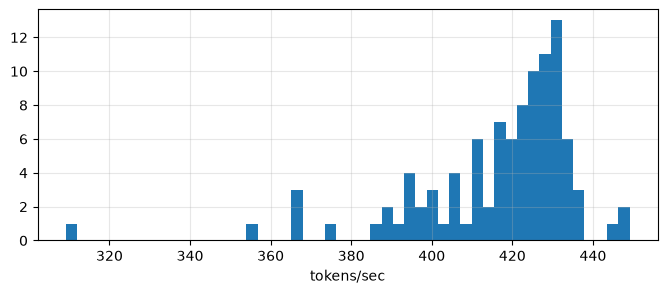

count    100.000000
mean     416.313311
std       20.805374
min      309.188474
25%      409.588430
50%      422.178209
75%      428.824418
max      449.087697
Name: tokens_per_sec, dtype: float64

In [16]:
plt.figure(figsize=(8, 3))
plt.hist(samples['tokens_per_sec'], bins = 50);
plt.grid(alpha=0.3)
plt.xlabel('tokens/sec')
plt.show()

samples['tokens_per_sec'].describe()

of course, the speed up is note free; the existence of a cache means that we are trading off memory for speed. below we consider how the cache sizes grow during inference. whilst for our model this is a small cost, as the stories are short and the context window is not long; models like Claude can have up to 1 million tokens in the context window, which is massive!